In [1]:
import sys
!{sys.executable} -m pip install -U "transformers>=4.45.0" "huggingface-hub<1.0,>=0.34.0" datasets "pyarrow<18"  -qq

In [2]:
from pathlib import Path

# # Add project root to sys.path
# ROOT_DIR = Path(r"D:\projects\AI_Visualization\traffic-sign-robustness")
# if str(ROOT_DIR) not in sys.path:
#     sys.path.insert(0, str(ROOT_DIR))
from pathlib import Path
import sys

# Dynamically find the project root by walking up from the current working directory
# until we find the folder that contains 'shared'
current_dir = Path.cwd()
root_dir = current_dir
while not (root_dir / "shared").exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent

# If 'shared' isn't found going up, check common relative locations (e.g., 1 or 2 levels up)
if not (root_dir / "shared").exists():
    for parent in current_dir.parents:
        if (parent / "shared").exists():
            root_dir = parent
            break

ROOT_DIR = root_dir

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

# Verify shared modules
from shared import class_mapping, dataset_loader, model_loader

print(f"Project root: {ROOT_DIR}")
print("Shared modules loaded successfully.")

Project root: D:\projects\AI_Visualization\traffic-sign-robustness
Shared modules loaded successfully.


In [3]:
# All Imports and Pytorch Ko Lagi
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from tqdm.auto import tqdm
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# For Model and processor
loaded_outputs = model_loader.load_model()

# Dynamically assign model and processor regardless of tuple order
model = None
processor = None
loader_device = None

for item in loaded_outputs:
    if hasattr(item, "to") and hasattr(item, "eval"):
        model = item
    elif hasattr(item, "__call__") and ("processor" in type(item).__name__.lower() or "feature" in type(item).__name__.lower()):
        processor = item
    elif isinstance(item, (torch.device, str)):
        loader_device = torch.device(item)

if loader_device is not None:
    device = loader_device

model.to(device)
model.eval()

print(f"Model ({type(model).__name__}) and Processor ({type(processor).__name__}) loaded successfully on {device}!")

Using device: cpu


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
C:\Users\acer\anaconda3\envs\cvW2025\Lib\site-packages\transformers\models\vit\feature_extraction_vit.py:30: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(


Model (ViTForImageClassification) and Processor (ViTFeatureExtractor) loaded successfully on cpu!


In [4]:
# 1. Load the split
test_split = dataset_loader.load_split(split="test")
print(f"Total test samples: {len(test_split)}")

# Extract label names directly from the model configuration or dataset features
def get_label_name(label_id: int) -> str:
    # Option A: Read from the shared module if available
    for attr in dir(class_mapping):
        if not attr.startswith("__"):
            val = getattr(class_mapping, attr)
            if isinstance(val, dict) and label_id in val:
                return str(val[label_id])
            if callable(val):
                try:
                    res = val(label_id)
                    if res:
                        return str(res)
                except Exception:
                    pass
    
    # Option B: Read directly from Hugging Face Model config (id2label)
    if "model" in globals() and hasattr(model, "config") and hasattr(model.config, "id2label"):
        id2label = model.config.id2label
        # Some configs store keys as ints, some as strings
        if label_id in id2label:
            return str(id2label[label_id])
        if str(label_id) in id2label:
            return str(id2label[str(label_id)])

    # Option C: Read from Hugging Face Dataset features ClassLabel
    if hasattr(test_split, "features") and "label" in test_split.features:
        feature = test_split.features["label"]
        if hasattr(feature, "int2str"):
            return feature.int2str(label_id)
            
    return f"Class_{label_id}"

first_sample = test_split[0]
label_id = first_sample["label"]
print(f"Sample keys: {list(first_sample.keys())}")
print(f"Label ID: {label_id} -> Class: {get_label_name(label_id)}")

Total test samples: 12630
Sample keys: ['image', 'label']
Label ID: 0 -> Class: Speed limit (20km/h)


In [5]:
import os

EVAL_CONDITIONS = ["test", "motion_blur", "gaussian_noise"]
CACHE_FILE = ROOT_DIR / "ai_aided" / "P2" / "predictions_files" / "predictions_cache.parquet"

# Check if cache already exists
if CACHE_FILE.exists():
    print(f"Loading cached predictions from {CACHE_FILE}")
    df_all = pd.read_parquet(CACHE_FILE)
else:
    all_dfs = []
    for split in EVAL_CONDITIONS:
        # Check if individual split was partially saved
        split_cache = ROOT_DIR / "ai_aided" / "P2" / "predictions_files" / f"preds_{split}.parquet"
        if split_cache.exists():
            print(f"Loading existing split cache for {split}...")
            df_split = pd.read_parquet(split_cache)
        else:
            print(f"\n--- Starting full evaluation for: {split} ---")
            # Using batch_size=32 for CPU throughput
            df_split = evaluate_condition_batched(split, batch_size=32)
            df_split.to_parquet(split_cache)
            print(f"Saved {split} predictions to {split_cache}")
        all_dfs.append(df_split)
        
    df_all = pd.concat(all_dfs, ignore_index=True)
    df_all.to_parquet(CACHE_FILE)
    print(f"\nAll splits saved to combined cache at {CACHE_FILE}")

print(f"\nTotal evaluated samples: {len(df_all)}")
summary_table = df_all.groupby("split").agg(
    accuracy=("correct", "mean"),
    mean_confidence=("confidence", "mean"),
    sample_count=("correct", "count")
)
summary_table["accuracy"] = (summary_table["accuracy"] * 100).round(2).astype(str) + "%"
summary_table["mean_confidence"] = summary_table["mean_confidence"].round(4)
display(summary_table)

Loading cached predictions from D:\projects\AI_Visualization\traffic-sign-robustness\ai_aided\P2\predictions_files\predictions_cache.parquet

Total evaluated samples: 37890


,accuracy,mean_confidence,sample_count
split,,,
gaussian_noise,85.0%,0.9426,12630
motion_blur,92.68%,0.9660,12630
test,95.38%,0.9776,12630


Saved distribution plot to D:\projects\AI_Visualization\traffic-sign-robustness\ai_aided\P2\figures_P2\confidence_distributions.png


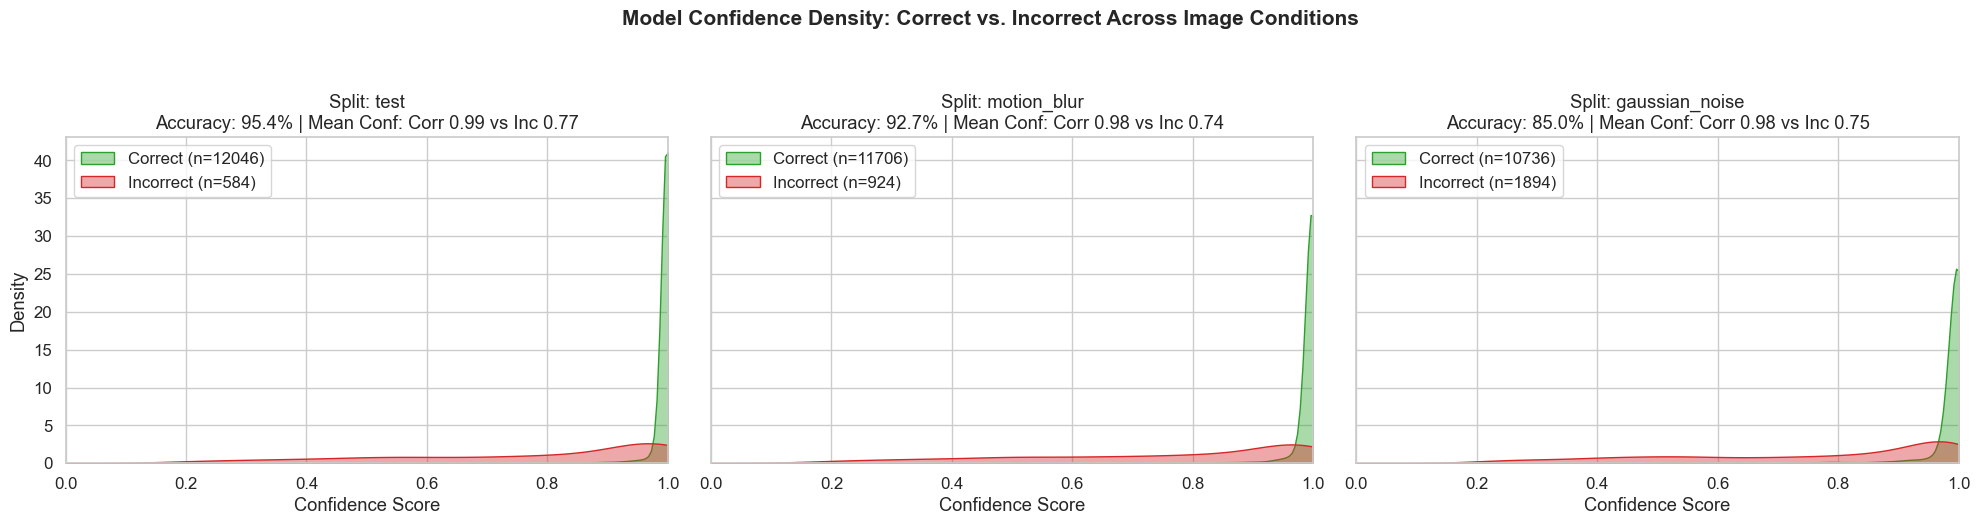

In [6]:
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)

for ax, split in zip(axes, EVAL_CONDITIONS):
    sub = df_all[df_all["split"] == split]
    
    corr = sub[sub["correct"] == True]["confidence"] # Correct Confidence
    inc = sub[sub["correct"] == False]["confidence"] # Incorrect Confidence
    
    sns.kdeplot(
        data=corr, ax=ax, label=f"Correct (n={len(corr)})",
        fill=True, color="#2ca02c", alpha=0.4, common_norm=False, clip=(0, 1)
    )
    if len(inc) > 0:
        sns.kdeplot(
            data=inc, ax=ax, label=f"Incorrect (n={len(inc)})",
            fill=True, color="#d62728", alpha=0.4, common_norm=False, clip=(0, 1)
        )
    
    acc = sub["correct"].mean() * 100
    mean_corr = corr.mean() if len(corr) > 0 else 0
    mean_inc = inc.mean() if len(inc) > 0 else 0
    
    ax.set_title(f"Split: {split}\nAccuracy: {acc:.1f}% | Mean Conf: Corr {mean_corr:.2f} vs Inc {mean_inc:.2f}")
    ax.set_xlabel("Confidence Score")
    ax.set_xlim(0, 1.0)
    ax.legend(loc="upper left")

axes[0].set_ylabel("Density")
plt.suptitle("Model Confidence Density: Correct vs. Incorrect Across Image Conditions", y=1.05, fontsize=15, weight="bold")
plt.tight_layout()

# Save figure
fig_path = ROOT_DIR / "ai_aided" / "P2" / "figures_P2" / "confidence_distributions.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved distribution plot to {fig_path}")
plt.show()

In [7]:
# Filter high-confidence failures
high_conf_errors = df_all[(df_all["correct"] == False) & (df_all["confidence"] >= 0.85)].copy()
print(f"Total High-Confidence Errors (Conf >= 0.85): {len(high_conf_errors)}")

# Group by corruption split and confusion pair
high_conf_summary = (
    high_conf_errors.groupby(["split", "true_name", "predicted_name"])
    .size()
    .reset_index(name="error_count")
    .sort_values(by="error_count", ascending=False)
)

print("\nTop 10 Most Frequent High-Confidence Confusions:")
display(high_conf_summary.head(10))

Total High-Confidence Errors (Conf >= 0.85): 1653

Top 10 Most Frequent High-Confidence Confusions:


,split,true_name,predicted_name,error_count
6,gaussian_noise,Ahead only,Speed limit (60km/h),109
85,gaussian_noise,Priority road,Roundabout mandatory,82
341,test,Traffic signals,General caution,48
170,gaussian_noise,Traffic signals,General caution,43
195,motion_blur,Ahead only,Speed limit (60km/h),40
313,test,Priority road,Roundabout mandatory,40
227,motion_blur,Priority road,Roundabout mandatory,35
217,motion_blur,Keep right,No entry,32
62,gaussian_noise,No passing,Speed limit (60km/h),30
300,test,Keep right,No entry,28


In [8]:
import ipywidgets as widgets
from IPython.display import display

# Dropdown & slider filters
split_dd = widgets.Dropdown(options=EVAL_CONDITIONS, value="motion_blur", description="Split:")
filter_dd = widgets.Dropdown(options=["Only Incorrect", "High-Conf Incorrect (>=0.85)", "Only Correct", "All"], value="High-Conf Incorrect (>=0.85)", description="Filter:")
idx_slider = widgets.IntSlider(value=0, min=0, max=10, step=1, description="Index:")

out_widget = widgets.Output()

def render_explorer(*args):
    out_widget.clear_output()
    
    # Filter dataset according to UI controls
    sub = df_all[df_all["split"] == split_dd.value]
    if filter_dd.value == "Only Incorrect":
        sub = sub[sub["correct"] == False]
    elif filter_dd.value == "High-Conf Incorrect (>=0.85)":
        sub = sub[(sub["correct"] == False) & (sub["confidence"] >= 0.85)]
    elif filter_dd.value == "Only Correct":
        sub = sub[sub["correct"] == True]
        
    if len(sub) == 0:
        with out_widget:
            print("No samples match criteria.")
        return
        
    idx_slider.max = max(0, len(sub) - 1)
    current_idx = min(idx_slider.value, idx_slider.max)
    row = sub.iloc[current_idx]
    
    # Retrieve original image
    ds = dataset_loader.load_split(split=row["split"])
    img = ds[int(row["image_id"])]["image"]
    
    # Plot image and top-5 probabilities
    with out_widget:
        fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={'width_ratios': [1, 1.4]})
        
        # Left: Original traffic sign image
        ax_img.imshow(img)
        ax_img.axis("off")
        color = "green" if row["correct"] else "red"
        ax_img.set_title(
            f"Image ID: {row['image_id']} ({row['split']})\nTrue: {row['true_name']}\nPred: {row['predicted_name']}",
            color=color, fontsize=11, weight="bold"
        )
        
        # Right: Top-5 prediction confidence scores
        scores = np.array(row["class_scores"])
        top5_idx = np.argsort(scores)[-5:]
        top5_probs = scores[top5_idx]
        top5_labels = [get_label_name(i) for i in top5_idx]
        
        bar_colors = ["#2ca02c" if i == row["true_label"] else "#1f77b4" for i in top5_idx]
        ax_bar.barh(range(5), top5_probs, color=bar_colors)
        ax_bar.set_yticks(range(5))
        ax_bar.set_yticklabels(top5_labels, fontsize=9)
        ax_bar.set_xlim(0, 1.05)
        ax_bar.set_xlabel("Predicted Probability")
        ax_bar.set_title(f"Model Top-5 Predictions (Top Conf: {row['confidence']:.2f})")
        
        plt.tight_layout()
        fig_path = ROOT_DIR / "ai_aided"  / "P2" / "figures_P2" / "confidence_predictions.png"
        plt.savefig(fig_path, dpi=300, bbox_inches="tight")
        print(f"Saved distribution plot to {fig_path}")
        plt.show()

split_dd.observe(render_explorer, names="value")
filter_dd.observe(render_explorer, names="value")
idx_slider.observe(render_explorer, names="value")

controls = widgets.VBox([
    widgets.HBox([split_dd, filter_dd]),
    idx_slider
])
display(controls, out_widget)
render_explorer()

Output()